In [1]:
# Install the UCI dataset access package
!pip install -q ucimlrepo

# Import required libraries
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

# Load the UCI Automobile dataset
automobile = fetch_ucirepo(id=10)

# Combine features and target into one DataFrame
X = automobile.data.features
y = automobile.data.targets
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully
Dataset shape: (205, 26)

Column names:
['price', 'highway-mpg', 'city-mpg', 'peak-rpm', 'horsepower', 'compression-ratio', 'stroke', 'bore', 'fuel-system', 'engine-size', 'num-of-cylinders', 'engine-type', 'curb-weight', 'height', 'width', 'length', 'wheel-base', 'engine-location', 'drive-wheels', 'body-style', 'num-of-doors', 'aspiration', 'fuel-type', 'make', 'normalized-losses', 'symboling']


In [2]:
# Save the raw dataset
raw_dataset_path = "automobile_raw_dataset.csv"
df.to_csv(raw_dataset_path, index=False)

print("Raw dataset saved successfully")
print("File name:", raw_dataset_path)

Raw dataset saved successfully
File name: automobile_raw_dataset.csv


In [3]:
# Inspect the dataset
print("First 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

First 5 rows:


,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,fuel-system,engine-size,...,wheel-base,engine-location,drive-wheels,body-style,num-of-doors,aspiration,fuel-type,make,normalized-losses,symboling
0,13495.0,27,21,5000.0,111.0,9.0,2.68,3.47,mpfi,130,...,88.6,front,rwd,convertible,2.0,std,gas,alfa-romero,NaN,3
1,16500.0,27,21,5000.0,111.0,9.0,2.68,3.47,mpfi,130,...,88.6,front,rwd,convertible,2.0,std,gas,alfa-romero,NaN,3
2,16500.0,26,19,5000.0,154.0,9.0,3.47,2.68,mpfi,152,...,94.5,front,rwd,hatchback,2.0,std,gas,alfa-romero,NaN,1
3,13950.0,30,24,5500.0,102.0,10.0,3.40,3.19,mpfi,109,...,99.8,front,fwd,sedan,4.0,std,gas,audi,164.0,2
4,17450.0,22,18,5500.0,115.0,8.0,3.40,3.19,mpfi,136,...,99.4,front,4wd,sedan,4.0,std,gas,audi,164.0,2



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   price              201 non-null    float64
 1   highway-mpg        205 non-null    int64  
 2   city-mpg           205 non-null    int64  
 3   peak-rpm           203 non-null    float64
 4   horsepower         203 non-null    float64
 5   compression-ratio  205 non-null    float64
 6   stroke             201 non-null    float64
 7   bore               201 non-null    float64
 8   fuel-system        205 non-null    object 
 9   engine-size        205 non-null    int64  
 10  num-of-cylinders   205 non-null    int64  
 11  engine-type        205 non-null    object 
 12  curb-weight        205 non-null    int64  
 13  height             205 non-null    float64
 14  width              205 non-null    float64
 15  length             205 non-null    float64
 16  whee

In [4]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", missing_values.sum())

Missing values by column:
price                 4
peak-rpm              2
horsepower            2
stroke                4
bore                  4
num-of-doors          2
normalized-losses    41
dtype: int64

Total missing values: 59


In [5]:
# Remove rows where the target variable (price) is missing
df = df.dropna(subset=["price"]).copy()

print("Rows after removing missing target values:", len(df))
print("Missing price values:", df["price"].isnull().sum())

Rows after removing missing target values: 201
Missing price values: 0


In [6]:
# Identify numerical and categorical columns
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['price', 'highway-mpg', 'city-mpg', 'peak-rpm', 'horsepower', 'compression-ratio', 'stroke', 'bore', 'engine-size', 'num-of-cylinders', 'curb-weight', 'height', 'width', 'length', 'wheel-base', 'num-of-doors', 'normalized-losses', 'symboling']

Categorical columns:
['fuel-system', 'engine-type', 'engine-location', 'drive-wheels', 'body-style', 'aspiration', 'fuel-type', 'make']


In [7]:
# Fill missing numerical values using the median
for column in numerical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].median())

print("Missing numerical values after imputation:")
print(df[numerical_columns].isnull().sum().sum())

Missing numerical values after imputation:
0


In [8]:
# Fill missing categorical values using the mode
for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].mode()[0])

print("Missing values remaining in the dataset:", df.isnull().sum().sum())

Missing values remaining in the dataset: 0


In [9]:
# Final data quality check
print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (201, 26)
Total missing values: 0
Duplicate rows: 0


In [10]:
# Feature Engineering

# 1. Power-to-weight ratio
df["power_to_weight"] = df["horsepower"] / df["curb-weight"]

# 2. Engine size per cylinder
df["engine_size_per_cylinder"] = (
    df["engine-size"] / df["num-of-cylinders"]
)

# 3. Average fuel economy
df["average_mpg"] = (
    df["city-mpg"] + df["highway-mpg"]
) / 2

# 4. Approximate vehicle volume
df["vehicle_volume"] = (
    df["length"] * df["width"] * df["height"]
)

print("Feature engineering completed successfully.")
print("\nNew features:")
print([
    "power_to_weight",
    "engine_size_per_cylinder",
    "average_mpg",
    "vehicle_volume"
])

print("\nNew dataset shape:", df.shape)

Feature engineering completed successfully.

New features:
['power_to_weight', 'engine_size_per_cylinder', 'average_mpg', 'vehicle_volume']

New dataset shape: (201, 30)


In [11]:
# Check engineered features
engineered_features = [
    "power_to_weight",
    "engine_size_per_cylinder",
    "average_mpg",
    "vehicle_volume"
]

print(df[engineered_features].describe())

       power_to_weight  engine_size_per_cylinder  average_mpg  vehicle_volume
count       201.000000                201.000000   201.000000      201.000000
mean          0.039825                 28.935406    27.932836   619579.968378
std           0.009057                  5.056850     6.572801    79564.106791
min           0.019936                 19.750000    15.000000   452643.156000
25%           0.034188                 24.500000    22.500000   566490.600000
50%           0.037811                 27.500000    27.000000   601385.700000
75%           0.044223                 32.333333    32.000000   674493.768000
max           0.075109                 43.000000    51.500000   846007.659000


In [12]:
# Separate target variable and predictor variables

X = df.drop(columns=["price"])
y = df["price"]

print("Predictor dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget variable:")
print(y.describe())

Predictor dataset shape: (201, 29)
Target dataset shape: (201,)

Target variable:
count      201.000000
mean     13207.129353
std       7947.066342
min       5118.000000
25%       7775.000000
50%      10295.000000
75%      16500.000000
max      45400.000000
Name: price, dtype: float64


In [13]:
# Convert categorical variables into numerical dummy variables
X_encoded = pd.get_dummies(X, drop_first=True)

print("Original predictor columns:", X.shape[1])
print("Encoded predictor columns:", X_encoded.shape[1])

print("\nEncoded dataset shape:", X_encoded.shape)

Original predictor columns: 29
Encoded predictor columns: 63

Encoded dataset shape: (201, 63)


In [14]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (160, 63)
Testing features: (41, 63)
Training target: (160,)
Testing target: (41,)


In [15]:
from sklearn.linear_model import LinearRegression

# Train the baseline Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Generate predictions on the test set
y_pred_linear = linear_model.predict(X_test)

# Calculate evaluation metrics
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Performance")
print("--------------------------------")
print(f"MAE  : {mae_linear:.2f}")
print(f"RMSE : {rmse_linear:.2f}")
print(f"R²   : {r2_linear:.4f}")

Linear Regression Performance
--------------------------------
MAE  : 1806.31
RMSE : 2857.71
R²   : 0.9333


In [17]:
from sklearn.ensemble import RandomForestRegressor

# Train Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    max_features="sqrt"
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [18]:
# Generate Random Forest predictions
y_pred_rf = rf_model.predict(X_test)

# Calculate evaluation metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("-------------------------")
print(f"MAE  : {mae_rf:.2f}")
print(f"RMSE : {rmse_rf:.2f}")
print(f"R²   : {r2_rf:.4f}")

Random Forest Performance
-------------------------
MAE  : 2280.49
RMSE : 3748.02
R²   : 0.8852


In [19]:
from sklearn.ensemble import GradientBoostingRegressor

# Train Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully.")

Gradient Boosting model trained successfully.


In [20]:
# Generate Gradient Boosting predictions
y_pred_gb = gb_model.predict(X_test)

# Calculate evaluation metrics
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Performance")
print("----------------------------")
print(f"MAE  : {mae_gb:.2f}")
print(f"RMSE : {rmse_gb:.2f}")
print(f"R²   : {r2_gb:.4f}")

Gradient Boosting Performance
----------------------------
MAE  : 1602.36
RMSE : 2506.13
R²   : 0.9487


In [21]:
# Calculate feature importance from the Gradient Boosting model
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 most important features:")
display(feature_importance.head(15))

Top 15 most important features:


,Feature,Importance
9,curb-weight,0.407141
7,engine-size,0.292234
1,city-mpg,0.049527
11,width,0.043845
0,highway-mpg,0.040167
3,horsepower,0.034949
8,num-of-cylinders,0.021402
12,length,0.017638
13,wheel-base,0.016097
19,average_mpg,0.013514


In [22]:
# Compare actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred_gb
})

comparison["Absolute Error"] = abs(
    comparison["Actual Price"] - comparison["Predicted Price"]
)

comparison = comparison.sort_values(
    by="Absolute Error"
).reset_index(drop=True)

print("Sample actual vs predicted prices:")
display(comparison.head(10))

print("\nAverage absolute error:", comparison["Absolute Error"].mean())
print("Maximum absolute error:", comparison["Absolute Error"].max())

Sample actual vs predicted prices:


,Actual Price,Predicted Price,Absolute Error
0,6669.0,6630.367521,38.632479
1,7775.0,7908.759359,133.759359
2,10795.0,11011.352393,216.352393
3,35056.0,34824.860403,231.139597
4,6488.0,6246.978465,241.021535
5,18150.0,17859.627592,290.372408
6,9639.0,9346.160519,292.839481
7,7689.0,8019.938882,330.938882
8,6855.0,6470.776156,384.223844
9,6295.0,5901.192312,393.807688



Average absolute error: 1602.3636318194683
Maximum absolute error: 10463.782921498441


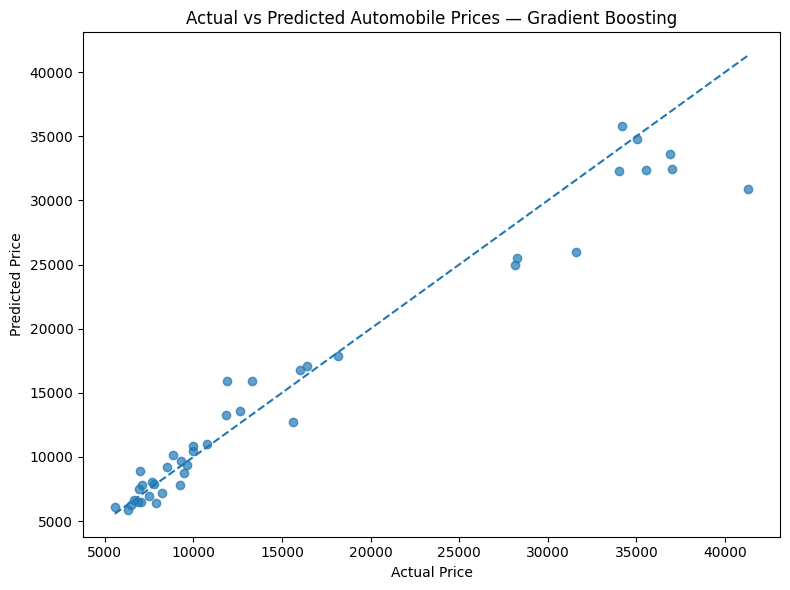

In [23]:
import matplotlib.pyplot as plt

# Plot actual vs predicted prices
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_gb, alpha=0.7)

# Perfect prediction reference line
min_price = min(y_test.min(), y_pred_gb.min())
max_price = max(y_test.max(), y_pred_gb.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Automobile Prices — Gradient Boosting")
plt.tight_layout()

plt.show()

In [24]:
# Residual analysis
residuals = y_test.values - y_pred_gb

print("Residual Analysis")
print("-----------------")
print(f"Mean residual: {residuals.mean():.2f}")
print(f"Minimum residual: {residuals.min():.2f}")
print(f"Maximum residual: {residuals.max():.2f}")

# Check how many predictions are within different error ranges
absolute_errors = np.abs(residuals)

print("\nPrediction accuracy ranges:")
print(f"Within ₹1,000 error : {(absolute_errors <= 1000).sum()} out of {len(y_test)}")
print(f"Within ₹2,000 error : {(absolute_errors <= 2000).sum()} out of {len(y_test)}")
print(f"Within ₹5,000 error : {(absolute_errors <= 5000).sum()} out of {len(y_test)}")

Residual Analysis
-----------------
Mean residual: 614.72
Minimum residual: -4050.11
Maximum residual: 10463.78

Prediction accuracy ranges:
Within ₹1,000 error : 23 out of 41
Within ₹2,000 error : 31 out of 41
Within ₹5,000 error : 39 out of 41


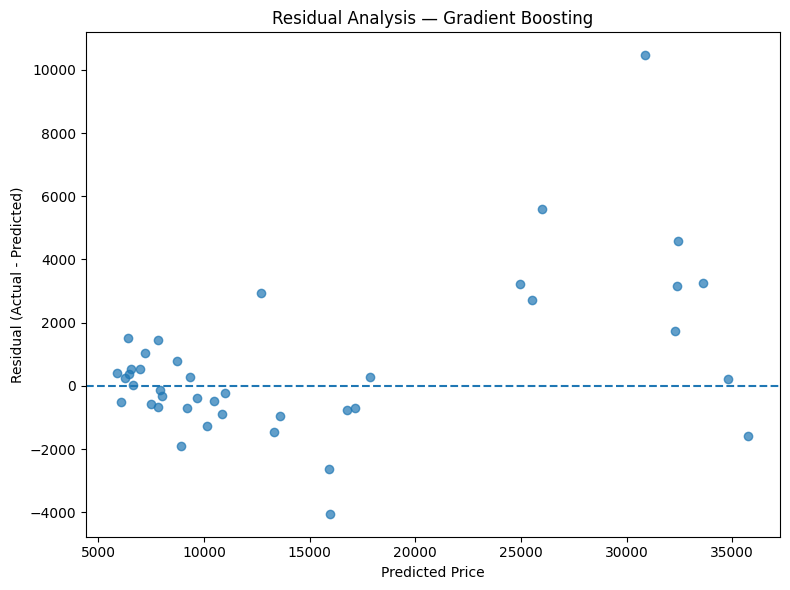

In [25]:
# Plot residuals
plt.figure(figsize=(8, 6))

plt.scatter(y_pred_gb, residuals, alpha=0.7)

# Zero-residual reference line
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis — Gradient Boosting")
plt.tight_layout()

plt.show()

In [26]:
# Save the cleaned and feature-engineered dataset
processed_dataset_path = "automobile_price_prediction_dataset.csv"

df.to_csv(processed_dataset_path, index=False)

print("Processed dataset saved successfully.")
print("File name:", processed_dataset_path)
print("Dataset shape:", df.shape)

Processed dataset saved successfully.
File name: automobile_price_prediction_dataset.csv
Dataset shape: (201, 30)


In [27]:
from google.colab import files

# Download the processed dataset
files.download("automobile_price_prediction_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>